# *Loading the csv file and importing required libraries*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import statistics

# ---------------------------------------------------------------------------
# Find the project root so this notebook runs on ANY machine.
#
# A bare filename only works if the CSV sits beside the notebook. A fixed path
# like "C:/Users/Hassan/..." works on one machine only. Instead we walk up
# from the current folder until we find the "data" directory, then read from
# there. Works whether Jupyter is started in the project root or in notebooks/.
# ---------------------------------------------------------------------------
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent

DATA = ROOT / "data"
print("project root:", ROOT)
print("data folder :", DATA)

df = pd.read_csv(DATA / "employee dataset.csv")
df


project root: C:\Users\Hassan\Desktop\DATA ANALYSIS PROJECTS\employee salaries analysis
data folder : C:\Users\Hassan\Desktop\DATA ANALYSIS PROJECTS\employee salaries analysis\data


,EmployeeID,Name,Age,City,Salary,JoinDate
0,1,Alice,25.0,Nairobi,55000.0,15/01/2025
1,2,Bob,NaN,Mombasa,62000.0,10/02/2025
2,3,Charlie,29.0,Kisumu,NaN,18/02/2025
3,4,Alice,25.0,Nairobi,55000.0,15/01/2025
4,5,Diana,31.0,NaN,70000.0,01/03/2025
5,6,Evan,27.0,Nakuru,48000.0,15/03/2025
6,7,Faith,-5.0,Eldoret,51000.0,02/04/2025
7,8,George,40.0,Nairobi,900000.0,18/04/2025
8,9,NaN,35.0,Kisumu,61000.0,05/05/2025
9,10,Hassan,28.0,Mombasa,58000.0,20/05/2025


In [2]:
df

,EmployeeID,Name,Age,City,Salary,JoinDate
0,1,Alice,25.0,Nairobi,55000.0,15/01/2025
1,2,Bob,NaN,Mombasa,62000.0,10/02/2025
2,3,Charlie,29.0,Kisumu,NaN,18/02/2025
3,4,Alice,25.0,Nairobi,55000.0,15/01/2025
4,5,Diana,31.0,NaN,70000.0,01/03/2025
5,6,Evan,27.0,Nakuru,48000.0,15/03/2025
6,7,Faith,-5.0,Eldoret,51000.0,02/04/2025
7,8,George,40.0,Nairobi,900000.0,18/04/2025
8,9,NaN,35.0,Kisumu,61000.0,05/05/2025
9,10,Hassan,28.0,Mombasa,58000.0,20/05/2025


# *Dataset Overview*

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   EmployeeID  10 non-null     int64  
 1   Name        9 non-null      object 
 2   Age         9 non-null      float64
 3   City        9 non-null      object 
 4   Salary      9 non-null      float64
 5   JoinDate    10 non-null     object 
dtypes: float64(2), int64(1), object(3)
memory usage: 612.0+ bytes


# *Dropping duplicates*

In [4]:
df = df.drop_duplicates(subset=["Name", "Age", "City", "Salary", "JoinDate"])

In [5]:
df.dtypes

EmployeeID      int64
Name           object
Age           float64
City           object
Salary        float64
JoinDate       object
dtype: object

# *Statistical summary check*

In [6]:
df.describe()

,EmployeeID,Age,Salary
count,9.000000,8.000000,8.000000
mean,5.666667,26.250000,163125.000000
std,3.162278,13.509256,297820.865382
min,1.000000,-5.000000,48000.000000
25%,3.000000,26.500000,54000.000000
50%,6.000000,28.500000,59500.000000
75%,8.000000,32.000000,64000.000000
max,10.000000,40.000000,900000.000000


# *Checking missing values*

In [7]:
df.isnull().sum()

EmployeeID    0
Name          1
Age           1
City          1
Salary        1
JoinDate      0
dtype: int64

# *Filling missing name*

In [8]:
df = df.copy()
df["Name"]=(df["Name"].fillna("Jamal"))
df

,EmployeeID,Name,Age,City,Salary,JoinDate
0,1,Alice,25.0,Nairobi,55000.0,15/01/2025
1,2,Bob,NaN,Mombasa,62000.0,10/02/2025
2,3,Charlie,29.0,Kisumu,NaN,18/02/2025
4,5,Diana,31.0,NaN,70000.0,01/03/2025
5,6,Evan,27.0,Nakuru,48000.0,15/03/2025
6,7,Faith,-5.0,Eldoret,51000.0,02/04/2025
7,8,George,40.0,Nairobi,900000.0,18/04/2025
8,9,Jamal,35.0,Kisumu,61000.0,05/05/2025
9,10,Hassan,28.0,Mombasa,58000.0,20/05/2025


# *Filling missing age*

### A trap worth documenting

The first version of this notebook imputed the median age in **two passes**, and
both were contaminated:

1. It filled Bob's blank age using the median of `[-5, 25, 27, 28, 29, 31, 35, 40]`
   = **28.5** — but `-5` is invalid data, so it dragged the median down.
2. It then replaced Faith's `-5` and filled again, from a set that now included
   the just-imputed **28.5** = **28.75**.

Rounded, that produced **Bob = 28** and **Faith = 29** from what should have been
a single median — and neither value was the median of anything real.

**The fix:** remove invalid ages *first*, compute the median **once** from valid
ages only (`[25, 27, 28, 29, 31, 35, 40]` → **29**), and apply that one value to
every gap. The published figures do not change — but now they are correct by
construction rather than by accident.


In [9]:
df = df.copy()

# An age of -5 (Faith) is invalid data, not a real observation, so remove it
# BEFORE computing the median. Otherwise the invalid value drags the median
# down and every imputed age inherits the error.
df.loc[df["Age"] < 0, "Age"] = pd.NA

# One median, computed from valid ages only -> 29.
median_age = int(df["Age"].median())
print("median age (valid values only):", median_age)

df["Age"] = df["Age"].fillna(median_age)
df


median age (valid values only): 29


,EmployeeID,Name,Age,City,Salary,JoinDate
0,1,Alice,25.0,Nairobi,55000.0,15/01/2025
1,2,Bob,29.0,Mombasa,62000.0,10/02/2025
2,3,Charlie,29.0,Kisumu,NaN,18/02/2025
4,5,Diana,31.0,NaN,70000.0,01/03/2025
5,6,Evan,27.0,Nakuru,48000.0,15/03/2025
6,7,Faith,29.0,Eldoret,51000.0,02/04/2025
7,8,George,40.0,Nairobi,900000.0,18/04/2025
8,9,Jamal,35.0,Kisumu,61000.0,05/05/2025
9,10,Hassan,28.0,Mombasa,58000.0,20/05/2025


# *Replacing  the negative  age with correct age*

In [10]:
# The invalid -5 was already handled in the cell above, and both gaps were
# filled from a median computed on valid ages only. This cell just confirms
# there are no remaining nulls or invalid ages.
print("nulls in Age :", int(df["Age"].isna().sum()))
print("ages below 0 :", int((df["Age"] < 0).sum()))
print("Bob's age    :", int(df.loc[df["Name"] == "Bob", "Age"].iloc[0]))
print("Faith's age  :", int(df.loc[df["Name"] == "Faith", "Age"].iloc[0]))


nulls in Age : 0
ages below 0 : 0
Bob's age    : 29
Faith's age  : 29


# *Filling missing value in salary*

In [11]:
df = df.copy()
df["Salary"]=df["Salary"].fillna(df["Salary"].median())
df

,EmployeeID,Name,Age,City,Salary,JoinDate
0,1,Alice,25.0,Nairobi,55000.0,15/01/2025
1,2,Bob,29.0,Mombasa,62000.0,10/02/2025
2,3,Charlie,29.0,Kisumu,59500.0,18/02/2025
4,5,Diana,31.0,NaN,70000.0,01/03/2025
5,6,Evan,27.0,Nakuru,48000.0,15/03/2025
6,7,Faith,29.0,Eldoret,51000.0,02/04/2025
7,8,George,40.0,Nairobi,900000.0,18/04/2025
8,9,Jamal,35.0,Kisumu,61000.0,05/05/2025
9,10,Hassan,28.0,Mombasa,58000.0,20/05/2025


# *Checking most city frequency*

In [12]:
df["City"].mode()

0     Kisumu
1    Mombasa
2    Nairobi
Name: City, dtype: object

In [13]:
df.loc[:, "City"] = df["City"].fillna(df["City"].mode()[0])
df

,EmployeeID,Name,Age,City,Salary,JoinDate
0,1,Alice,25.0,Nairobi,55000.0,15/01/2025
1,2,Bob,29.0,Mombasa,62000.0,10/02/2025
2,3,Charlie,29.0,Kisumu,59500.0,18/02/2025
4,5,Diana,31.0,Kisumu,70000.0,01/03/2025
5,6,Evan,27.0,Nakuru,48000.0,15/03/2025
6,7,Faith,29.0,Eldoret,51000.0,02/04/2025
7,8,George,40.0,Nairobi,900000.0,18/04/2025
8,9,Jamal,35.0,Kisumu,61000.0,05/05/2025
9,10,Hassan,28.0,Mombasa,58000.0,20/05/2025


# *Checking outliers*

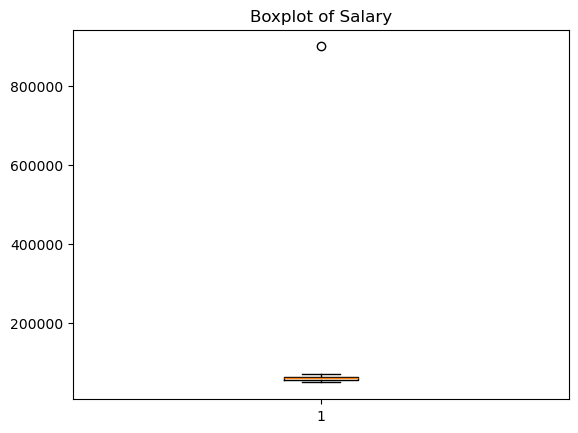

In [14]:
plt.boxplot(df["Salary"].dropna())
plt.title("Boxplot of Salary")
plt.show()

# *Detecting Salary Outliers Using the IQR Method*

In [15]:
# Tukey's fences, using median-excluded halves - the same definition the
# PDF report uses (generate_report.py -> tukey_fences), so the notebook,
# the report and the README all quote the same numbers.
#
# There are several valid ways to compute quartiles, and pandas' default
# .quantile() interpolates, which gives a different (also valid) fence.
# Using one definition everywhere is what makes the published figures
# reproducible from any artefact in the repo.
_salaries = sorted(df["Salary"].dropna())
_mid = len(_salaries) // 2
Q1 = statistics.median(_salaries[:_mid])
Q3 = statistics.median(_salaries[_mid + 1:])
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print(f"Q1 = {Q1:,.0f}  Q3 = {Q3:,.0f}  IQR = {IQR:,.0f}")
print(f"lower fence = {lower:,.0f}   upper fence = {upper:,.0f}")

outliers = df[(df["Salary"] < lower) | (df["Salary"] > upper)]
outliers

Q1 = 53,000  Q3 = 66,000  IQR = 13,000
lower fence = 33,500   upper fence = 85,500


,EmployeeID,Name,Age,City,Salary,JoinDate
7,8,George,40.0,Nairobi,900000.0,18/04/2025


# *Correcting the 'outlier"*

In [16]:
df.loc[df["Name"] == "George", "Salary"] = 90000
df

,EmployeeID,Name,Age,City,Salary,JoinDate
0,1,Alice,25.0,Nairobi,55000.0,15/01/2025
1,2,Bob,29.0,Mombasa,62000.0,10/02/2025
2,3,Charlie,29.0,Kisumu,59500.0,18/02/2025
4,5,Diana,31.0,Kisumu,70000.0,01/03/2025
5,6,Evan,27.0,Nakuru,48000.0,15/03/2025
6,7,Faith,29.0,Eldoret,51000.0,02/04/2025
7,8,George,40.0,Nairobi,90000.0,18/04/2025
8,9,Jamal,35.0,Kisumu,61000.0,05/05/2025
9,10,Hassan,28.0,Mombasa,58000.0,20/05/2025


# *Dropping duplicates*

In [17]:
df = df.drop_duplicates(subset=["Name", "Age", "City", "Salary", "JoinDate"]).copy()

# Removing a row leaves a gap in EmployeeID (Alice's duplicate was ID 4, so the
# IDs ran 1,2,3,5,6,7,8,9,10). Renumber to 1..N so the ID is a clean row number
# and matches the cleaned CSV. Without this, a notebook load and a pipeline load
# would disagree on the key, and an incremental load would re-write every row.
df["EmployeeID"] = range(1, len(df) + 1)
df

,EmployeeID,Name,Age,City,Salary,JoinDate
0,1,Alice,25.0,Nairobi,55000.0,15/01/2025
1,2,Bob,29.0,Mombasa,62000.0,10/02/2025
2,3,Charlie,29.0,Kisumu,59500.0,18/02/2025
4,4,Diana,31.0,Kisumu,70000.0,01/03/2025
5,5,Evan,27.0,Nakuru,48000.0,15/03/2025
6,6,Faith,29.0,Eldoret,51000.0,02/04/2025
7,7,George,40.0,Nairobi,90000.0,18/04/2025
8,8,Jamal,35.0,Kisumu,61000.0,05/05/2025
9,9,Hassan,28.0,Mombasa,58000.0,20/05/2025


# *Changing the join date into a correct format*

In [18]:

df.loc[:, "JoinDate"] = pd.to_datetime(df["JoinDate"], dayfirst=True)
df

,EmployeeID,Name,Age,City,Salary,JoinDate
0,1,Alice,25.0,Nairobi,55000.0,2025-01-15 00:00:00
1,2,Bob,29.0,Mombasa,62000.0,2025-02-10 00:00:00
2,3,Charlie,29.0,Kisumu,59500.0,2025-02-18 00:00:00
4,4,Diana,31.0,Kisumu,70000.0,2025-03-01 00:00:00
5,5,Evan,27.0,Nakuru,48000.0,2025-03-15 00:00:00
6,6,Faith,29.0,Eldoret,51000.0,2025-04-02 00:00:00
7,7,George,40.0,Nairobi,90000.0,2025-04-18 00:00:00
8,8,Jamal,35.0,Kisumu,61000.0,2025-05-05 00:00:00
9,9,Hassan,28.0,Mombasa,58000.0,2025-05-20 00:00:00


# *Rounding off age*

In [19]:
# No imputation left to do here - ages were filled once, correctly, above.
# This cell only enforces the integer dtype for the final table.
df["Age"] = df["Age"].round().astype(int)
df


,EmployeeID,Name,Age,City,Salary,JoinDate
0,1,Alice,25,Nairobi,55000.0,2025-01-15 00:00:00
1,2,Bob,29,Mombasa,62000.0,2025-02-10 00:00:00
2,3,Charlie,29,Kisumu,59500.0,2025-02-18 00:00:00
4,4,Diana,31,Kisumu,70000.0,2025-03-01 00:00:00
5,5,Evan,27,Nakuru,48000.0,2025-03-15 00:00:00
6,6,Faith,29,Eldoret,51000.0,2025-04-02 00:00:00
7,7,George,40,Nairobi,90000.0,2025-04-18 00:00:00
8,8,Jamal,35,Kisumu,61000.0,2025-05-05 00:00:00
9,9,Hassan,28,Mombasa,58000.0,2025-05-20 00:00:00


# *importing the df to sql*

In [20]:
from sqlalchemy import create_engine
from dotenv import load_dotenv
import os

load_dotenv()

user = os.getenv("DB_USER")
password = os.getenv("DB_PASSWORD")
host = os.getenv("DB_HOST")
port = os.getenv("DB_PORT")
database = os.getenv("DB_NAME")

engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}:{port}/{database}")

df.to_sql(
    name="employees",
    con=engine,
    if_exists="replace",   
    index=False
)
print("Data loaded into MySQL successfully.")

Data loaded into MySQL successfully.
